In [32]:
importlib.reload(utils_credit)

<module 'utils_credit' from 'c:\\Users\\DELL\\Desktop\\M2 France\\ML\\TPs\\TP-Anomalie-ML\\notebook\\utils_credit.py'>

# Biblio

In [33]:
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import importlib
import utils_credit
import numpy as np

In [34]:
# Import de nos fonctions utils
sys.path.append(os.path.abspath("."))
import utils_credit

print("Pandas version :", pd.__version__)
print("Numpy version  :", np.__version__)

Pandas version : 3.0.6
Numpy version  : 2.4.6


# 1. Préparer Credit Card

## a. Examiner les données

- Types des colonnes
- Recherche de valeurs manquantes
- Détection et suppression des doublons
- Proportion de fraudes
- Gestion de Time et découpage stratifié (60% Train / 20% Val / 20% Test)

### Examen initial (types, valeurs manquantes, doublons)

In [35]:
# Chargement brut pour inspection
df_raw = pd.read_csv("../data/creditcard.csv")

print(f"Dimensions : {df_raw.shape[0]} lignes, {df_raw.shape[1]} colonnes")
print(f"Valeurs manquantes totales : {df_raw.isna().sum().sum()}")

# Comptage des doublons
n_doublons = df_raw.duplicated().sum()
print(f"Nombre de doublons stricts : {n_doublons}")

# Affichage des types de variables
print(df_raw.dtypes.value_counts())


Dimensions : 284807 lignes, 31 colonnes
Valeurs manquantes totales : 0
Nombre de doublons stricts : 1081
float64    30
int64       1
Name: count, dtype: int64


### Nettoyage des doublons et calcul du déséquilibre

In [36]:
# Nettoyage via utils_credit (suppression des doublons)
df = utils_credit.load_clean_data("../data/creditcard.csv")

# Proportion de fraudes
comptes = df["Class"].value_counts()
pct_fraude = (comptes[1] / len(df)) * 100

print(f"Transactions normales (0) : {comptes[0]}")
print(f"Fraudes (1)               : {comptes[1]}")
print(f"Proportion de fraudes     : {pct_fraude:.3f}%")

Transactions normales (0) : 283253
Fraudes (1)               : 473
Proportion de fraudes     : 0.167%


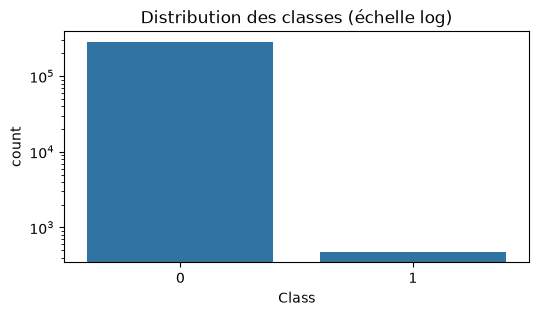

In [37]:
# Graphique simple du déséquilibre
plt.figure(figsize=(6, 3))
sns.countplot(x="Class", data=df)
plt.yscale("log")
plt.title("Distribution des classes (échelle log)")
plt.show()

### Découpage stratifié (60% Train / 20% Val / 20% Test)

In [38]:
# Découpage avec Time et Class écartés de X
X_train, X_val, X_test, y_train, y_val, y_test = utils_credit.split_data(
    df, random_state=42
)

# Vérification des effectifs et du taux de fraude
for nom, y_part in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
  n_f = (y_part == 1).sum()
  taux = (n_f / len(y_part)) * 100
  print(
      f"{nom:<5} : {len(y_part)} transactions | {n_f} fraudes"
      f" ({taux:.3f}%)"
  )


Train : 170235 transactions | 284 fraudes (0.167%)
Val   : 56745 transactions | 94 fraudes (0.166%)
Test  : 56746 transactions | 95 fraudes (0.167%)


### Analyse de Time et limites du découpage aléatoire

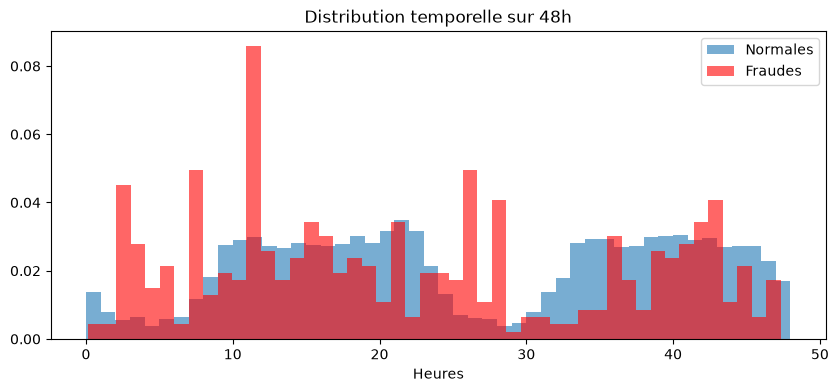

In [39]:
# Visualisation de la distribution de Time (en heures)
time_heures = df["Time"] / 3600

plt.figure(figsize=(10, 4))
plt.hist(
    time_heures[df["Class"] == 0],
    bins=48,
    alpha=0.6,
    label="Normales",
    density=True,
)
plt.hist(
    time_heures[df["Class"] == 1],
    bins=48,
    alpha=0.6,
    label="Fraudes",
    color="red",
    density=True,
)
plt.title("Distribution temporelle sur 48h")
plt.xlabel("Heures")
plt.legend()
plt.show()

#### Limites du découpage aléatoire par rapport à la variable Time :

1. **Fuite temporelle (Data leakage / interpolation) :**
   Un découpage aléatoire mélange les données du jour 1 et du jour 2. Le modèle risque donc d'apprendre sur des transactions du futur pour prédire des fraudes du passé, ce qui est impossible dans la réalité.

2. **Dérive de concept (Concept Drift) :**
   Les comportements légitimes suivent des cycles jour/nuit (creux la nuit, pics le jour), alors que les méthodes des fraudeurs s'adaptent et évoluent en permanence dans le temps.

3. **Inadéquation avec la production réelle :**
   En conditions réelles dans une banque, on s'entraîne toujours sur le passé ($t < T$) pour prédire sur le futur ($t \ge T$). Un découpage chronologique serait donc indispensable en pratique. Nous écartons `Time` des prédicteurs pour cette comparaison afin d'éviter qu'il n'apprenne des corrélations temporelles factices.


## b. Étude des échelles des variables et prétraitement

### Observer les échelles (Amount vs V1 à V28)

In [40]:
# 1. Statistiques de Amount
print("Statistiques de la variable Amount (Train)")
print(X_train["Amount"].describe())

# 2. Statistiques moyennes des variables V1 à V28
print("\nÉchelle des variables V1 à V28 (Train)")
v_cols = [col for col in X_train.columns if col.startswith("V")]
print("Moyenne générale de V1..V28     :", round(X_train[v_cols].mean().mean(), 4))
print("Écart-type moyen de V1..V28     :", round(X_train[v_cols].std().mean(), 4))
print("Valeur min de V1..V28 (extrême) :", round(X_train[v_cols].min().min(), 2))
print("Valeur max de V1..V28 (extrême) :", round(X_train[v_cols].max().max(), 2))


Statistiques de la variable Amount (Train)
count    170235.000000
mean         88.304887
std         243.916503
min           0.000000
25%           5.615000
50%          22.000000
75%          77.650000
max       18910.000000
Name: Amount, dtype: float64

Échelle des variables V1 à V28 (Train)
Moyenne générale de V1..V28     : 0.0005
Écart-type moyen de V1..V28     : 0.9702
Valeur min de V1..V28 (extrême) : -73.22
Valeur max de V1..V28 (extrême) : 38.12


### Visualiser la distribution de Amount

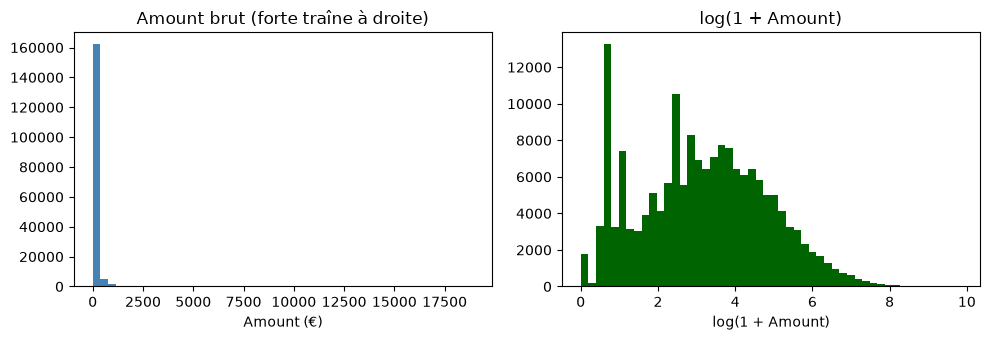

In [41]:
# Histogramme brut de Amount et avec log(1 + Amount)
plt.figure(figsize=(10, 3.5))

plt.subplot(1, 2, 1)
plt.hist(X_train["Amount"], bins=50, color="steelblue")
plt.title("Amount brut (forte traîne à droite)")
plt.xlabel("Amount (€)")

plt.subplot(1, 2, 2)
plt.hist(np.log1p(X_train["Amount"]), bins=50, color="darkgreen")
plt.title("log(1 + Amount)")
plt.xlabel("log(1 + Amount)")

plt.tight_layout()
plt.show()

#### Justification du prétraitement par famille d'algorithmes :

1. **Méthodes fondées sur les distances (LOF, k-NN dans SMOTE) :**
   - **Forte sensibilité à l'échelle :** La distance euclidienne calcule la somme des écarts au carré $\sum (x_i - y_i)^2$. Comme `Amount` varie entre 0 et 18 910 € alors que $V_1 \dots V_{28}$ varient entre -5 et +5, la variable `Amount` écraserait toutes les autres composantes.
   - **Pourquoi `RobustScaler` plutôt que `StandardScaler` ?** `StandardScaler` utilise la moyenne et l'écart-type, qui sont très déformés par les montants extrêmes (outliers). `RobustScaler` repose sur la **médiane** et l'**écart interquartile (IQR)**, ce qui le rend résilient aux montants atypiques.

2. **Modèles linéaires (Régression Logistique) :**
   - La régularisation ($L_2$) applique une pénalité uniforme sur les coefficients. Sans mise à l'échelle, le coefficient de `Amount` serait artificiellement écrasé par rapport à ceux des $V_i$.

3. **Modèles arborescents (Arbre de décision, Isolation Forest) :**
   - Ils sont **invariants aux changements d'échelle monotones** car leurs découpages univariés ($X_j \le \theta$) ne dépendent que du rang/ordre des valeurs. La mise à l'échelle ne change pas leurs décisions mais uniformise le pipeline.

4. **Variables $V_1$ à $V_{28}$ :**
   - Issues d'une ACP (PCA), elles sont déjà centrées en 0 et réduites. Étant anonymisées pour préserver le secret bancaire, toute interprétation métier causale est impossible ; nous les conservons donc sans transformation.


### Appliquer la mise à l'échelle (scale_amount)

In [42]:
X_train_s, X_val_s, X_test_s = utils_credit.scale_amount(X_train, X_val, X_test)

# Vérification : la médiane de Amount sur Train doit être à 0
print("Statistiques de Amount après RobustScaler (Train) :")
print(X_train_s["Amount"].describe().round(3))

Statistiques de Amount après RobustScaler (Train) :
count    170235.000
mean          0.920
std           3.386
min          -0.305
25%          -0.227
50%           0.000
75%           0.773
max         262.206
Name: Amount, dtype: float64


# 2. Comparer et prendre une décision

## a. Comparaison des modèles supervisés (Arbre de décision et Régression Logistique)


Pour chaque modèle, nous étudions 3 variantes :
1. Sans correction du déséquilibre
2. Avec pondération des classes (`class_weight='balanced'`)
3. Avec rééchantillonnage **SMOTE** (justifié par la création de données synthétiques fiables grâce à notre mise à l'échelle préalable).

Le rééchantillonnage est appliqué **exclusivement sur les données d'apprentissage** (`X_train_s`, `y_train`).

### Créer le jeu rééchantillonné avec SMOTE

In [43]:
from imblearn.over_sampling import SMOTE

# Application de SMOTE UNIQUEMENT sur le Train
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_s, y_train)

print(
    f"Effectifs Train initial : {len(y_train)} dont {(y_train == 1).sum()}"
    " fraudes"
)
print(
    f"Effectifs Train SMOTE   : {len(y_train_smote)} dont"
    f" {(y_train_smote == 1).sum()} fraudes"
)


Effectifs Train initial : 170235 dont 284 fraudes
Effectifs Train SMOTE   : 339902 dont 169951 fraudes


### Évaluer la Régression Logistique (3 variantes)

In [44]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
import utils_credit

# 1. Définition des 3 variantes
modeles_lr = {
    "LR (Sans correction)": LogisticRegression(max_iter=1000, random_state=42),
    "LR (Pondération classes)": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=42
    ),
    "LR (SMOTE)": LogisticRegression(max_iter=1000, random_state=42),
}

resultats_lr = []
scores_lr_dict = {}


In [45]:
# 2. Entraînement et calcul des scores sur la Validation
for nom, clf in modeles_lr.items():
  if "SMOTE" in nom:
    clf.fit(X_train_smote, y_train_smote)
  else:
    clf.fit(X_train_s, y_train)

  # Scores continus (probabilité de fraude)
  scores_val = clf.predict_proba(X_val_s)[:, 1]
  scores_lr_dict[nom] = scores_val

  ap = average_precision_score(y_val, scores_val)
  auc = roc_auc_score(y_val, scores_val)

  resultats_lr.append({
      "Modèle": nom,
      "AP (Validation)": round(ap, 4),
      "AUC-ROC": round(auc, 4),
  })

Régression Logistique : Comparaison des 3 variantes


,Modèle,AP (Validation),AUC-ROC
0,LR (Sans correction),0.6968,0.9697
1,LR (Pondération classes),0.6927,0.9713
2,LR (SMOTE),0.6905,0.9700


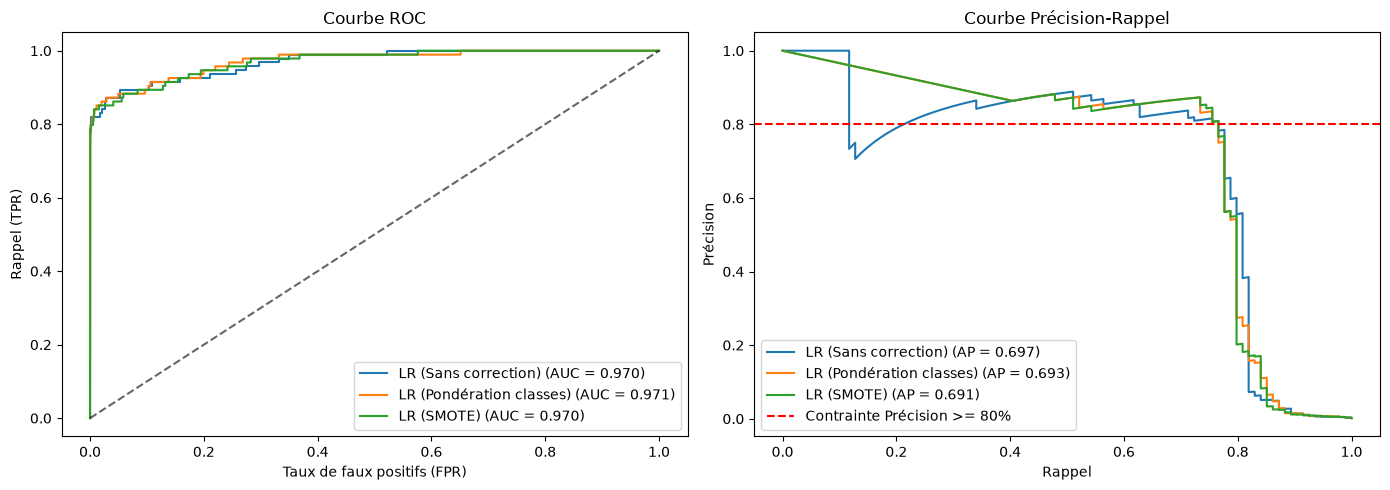

In [46]:
# 3. Affichage du tableau de comparaison
df_res_lr = pd.DataFrame(resultats_lr)
print("Régression Logistique : Comparaison des 3 variantes")
display(df_res_lr)

# 4. Tracé des courbes ROC et Précision-Rappel
utils_credit.tracer_courbes_roc_pr(y_val, scores_lr_dict)

### Évaluer l'Arbre de Décision (3 variantes)

In [47]:
from sklearn.tree import DecisionTreeClassifier

# 1. Définition des 3 variantes (profondeur max = 5 pour régulariser)
modeles_dt = {
    "Arbre (Sans correction)": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Arbre (Pondération classes)": DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=42
    ),
    "Arbre (SMOTE)": DecisionTreeClassifier(max_depth=5, random_state=42),
}

resultats_dt = []
scores_dt_dict = {}


In [48]:
# 2. Entraînement et calcul des scores sur la Validation
for nom, clf in modeles_dt.items():
  if "SMOTE" in nom:
    clf.fit(X_train_smote, y_train_smote)
  else:
    clf.fit(X_train_s, y_train)

  scores_val = clf.predict_proba(X_val_s)[:, 1]
  scores_dt_dict[nom] = scores_val

  ap = average_precision_score(y_val, scores_val)
  auc = roc_auc_score(y_val, scores_val)

  resultats_dt.append({
      "Modèle": nom,
      "AP (Validation)": round(ap, 4),
      "AUC-ROC": round(auc, 4),
  })

Arbre de Décision : Comparaison des 3 variantes


,Modèle,AP (Validation),AUC-ROC
0,Arbre (Sans correction),0.6684,0.8563
1,Arbre (Pondération classes),0.4343,0.8878
2,Arbre (SMOTE),0.3420,0.9628


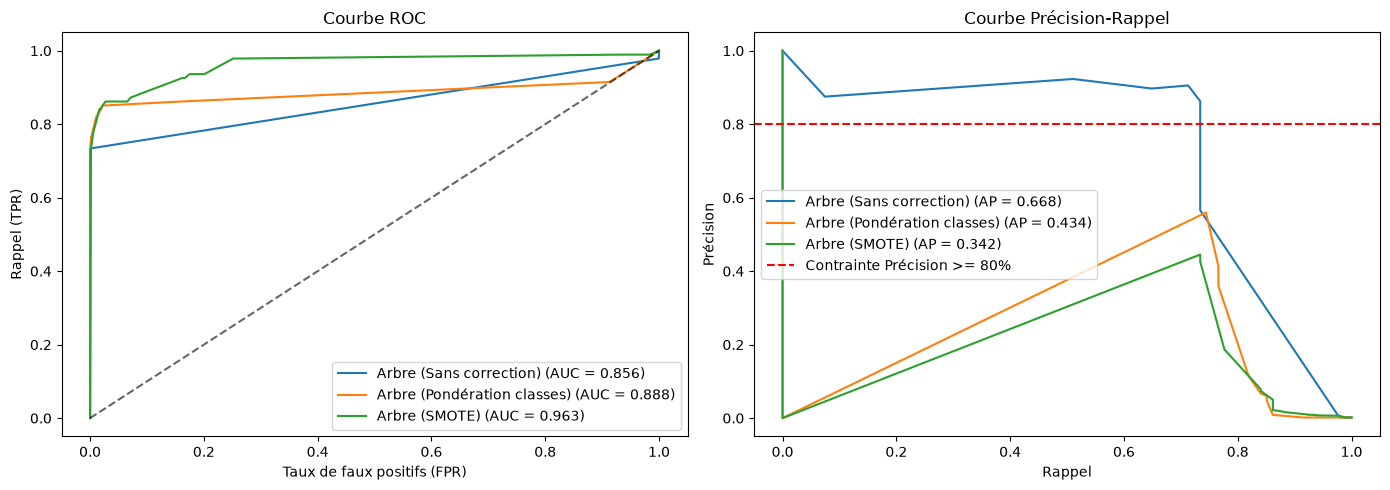

In [49]:
# 3. Affichage du tableau de comparaison
df_res_dt = pd.DataFrame(resultats_dt)
print("Arbre de Décision : Comparaison des 3 variantes")
display(df_res_dt)

# 4. Tracé des courbes ROC et Précision-Rappel
utils_credit.tracer_courbes_roc_pr(y_val, scores_dt_dict)

### Justification du choix de la méthode de rééchantillonnage (SMOTE) :

Parmi les méthodes proposées par le sujet, nous avons retenu **SMOTE** pour les raisons suivantes :
- **RandomUnderSampler** élimine aléatoirement plus de 99% des transactions normales, ce qui détruit une quantité massive d'informations représentatives.
- **RandomOverSampler** duplique à l'identique les mêmes fraudes existantes, favorisant le surapprentissage (*overfitting*).
- **Tomek Links** ne fait qu'un nettoyage frontière sans corriger le ratio extrême de 1 fraude pour 600 normales.
- **SMOTE (Synthetic Minority Over-sampling Technique)** génère de nouvelles fraudes synthétiques intelligentes par interpolation entre voisins réels dans l'espace des descripteurs. Notre mise à l'échelle préalable (`RobustScaler`) garantit que le calcul des plus proches voisins (k-NN) dans SMOTE est mathématiquement fiable et équilibré.

> **Règle méthodologique :** SMOTE est ajusté et appliqué **exclusivement sur les données d'apprentissage** (`X_train_s`). Les partitions de validation et de test restent dans leur distribution déséquilibrée réelle.

## b. Sélection des hyperparamètres (6 configurations par modèle)

Conformément aux consignes, nous testons au maximum 6 configurations par modèle :
- **Régression Logistique :** 2 valeurs de régularisation ($C=0.1$ et $C=1.0$) pour chacune des 3 variantes de déséquilibre (Sans correction, Balanced, SMOTE).
- **Arbre de décision :** 2 profondeurs maximales (`max_depth=3` et `max_depth=5`) pour chacune des 3 variantes. Des profondeurs limitées permettent de régulariser l'arbre et d'éviter le surapprentissage.

### Tester les 6 configurations de la Régression Logistique

In [50]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
import utils_credit

# 6 configurations
configs_lr = [
    {"C": 0.1, "variante": "Sans correction"},
    {"C": 1.0, "variante": "Sans correction"},
    {"C": 0.1, "variante": "Pondération"},
    {"C": 1.0, "variante": "Pondération"},
    {"C": 0.1, "variante": "SMOTE"},
    {"C": 1.0, "variante": "SMOTE"},
]

resultats_complets_lr = []
scores_6_lr = {}

In [51]:
for cfg in configs_lr:
  cw = "balanced" if cfg["variante"] == "Pondération" else None
  clf = LogisticRegression(
      C=cfg["C"], class_weight=cw, max_iter=1000, random_state=42
  )

  if cfg["variante"] == "SMOTE":
    clf.fit(X_train_smote, y_train_smote)
  else:
    clf.fit(X_train_s, y_train)

  scores_val = clf.predict_proba(X_val_s)[:, 1]

  # Sauvegarde des scores pour tracer la courbe ROC
  nom_cfg = f"LR ({cfg['variante']}, C={cfg['C']})"
  scores_6_lr[nom_cfg] = scores_val

  # Calcul des métriques au seuil optimal
  res = utils_credit.trouver_meilleur_seuil(
      y_val, scores_val, min_precision=0.80
  )
  res["C"] = cfg["C"]
  res["Variante"] = cfg["variante"]
  resultats_complets_lr.append(res)

KeyboardInterrupt: 

Régression Logistique : Évaluation des 6 configurations


,C,Variante,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées)
1,1.0,Sans correction,0.6968,0.9697,Atteint,0.075610,0.8090,0.7660,0.7869,0.8828,17,22
0,0.1,Sans correction,0.6959,0.9713,Atteint,0.080387,0.8068,0.7553,0.7802,0.8775,17,23
3,1.0,Pondération,0.6927,0.9713,Atteint,0.999994,0.8090,0.7660,0.7869,0.8828,17,22
5,1.0,SMOTE,0.6905,0.9700,Atteint,0.999998,0.8090,0.7660,0.7869,0.8828,17,22
2,0.1,Pondération,0.6901,0.9710,Atteint,0.999993,0.8090,0.7660,0.7869,0.8828,17,22
4,0.1,SMOTE,0.6895,0.9700,Atteint,0.999998,0.8090,0.7660,0.7869,0.8828,17,22


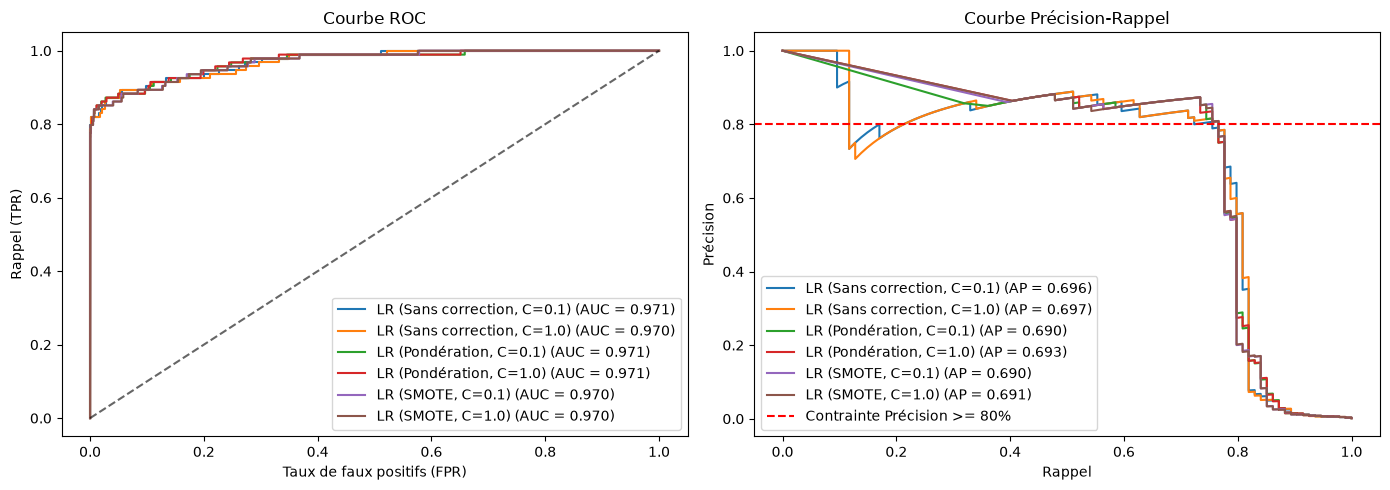

In [ ]:
# 1. Affichage du tableau d'évaluation
df_eval_lr = pd.DataFrame(resultats_complets_lr)
colonnes_ordre = [
    "C",
    "Variante",
    "AP",
    "AUC-ROC",
    "Contrainte (>=80%)",
    "Seuil",
    "Précision",
    "Rappel",
    "F1-score",
    "Balanced Accuracy",
    "FP (Fausses alertes)",
    "FN (Fraudes manquées)",
]
print("Régression Logistique : Évaluation des 6 configurations")
display(df_eval_lr[colonnes_ordre].sort_values(by="AP", ascending=False))

# 2. Tracé des courbes ROC et Précision-Rappel de ces 6 configurations
utils_credit.tracer_courbes_roc_pr(y_val, scores_6_lr)

### Tester les 6 configurations de l'Arbre de Décision

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# 6 configurations
configs_dt = [
    {"max_depth": 3, "variante": "Sans correction"},
    {"max_depth": 5, "variante": "Sans correction"},
    {"max_depth": 3, "variante": "Pondération"},
    {"max_depth": 5, "variante": "Pondération"},
    {"max_depth": 3, "variante": "SMOTE"},
    {"max_depth": 5, "variante": "SMOTE"},
]

resultats_complets_dt = []
scores_6_dt = {}

In [ ]:
for cfg in configs_dt:
  cw = "balanced" if cfg["variante"] == "Pondération" else None
  clf = DecisionTreeClassifier(
      max_depth=cfg["max_depth"], class_weight=cw, random_state=42
  )

  if cfg["variante"] == "SMOTE":
    clf.fit(X_train_smote, y_train_smote)
  else:
    clf.fit(X_train_s, y_train)

  scores_val = clf.predict_proba(X_val_s)[:, 1]

  nom_cfg = f"Arbre (prof={cfg['max_depth']}, {cfg['variante']})"
  scores_6_dt[nom_cfg] = scores_val

  res = utils_credit.trouver_meilleur_seuil(
      y_val, scores_val, min_precision=0.80
  )
  res["Profondeur"] = cfg["max_depth"]
  res["Variante"] = cfg["variante"]
  resultats_complets_dt.append(res)

Arbre de Décision : Évaluation des 6 configurations


,Profondeur,Variante,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées)
1,5,Sans correction,0.6684,0.8563,Atteint,0.050000,0.8625,0.7340,0.7931,0.8669,11,25
0,3,Sans correction,0.6308,0.8669,Atteint,0.300000,0.8312,0.6809,0.7485,0.8403,13,30
3,5,Pondération,0.4343,0.8878,Non atteint,0.998761,0.5600,0.7447,0.6393,0.8719,55,24
2,3,Pondération,0.3588,0.9469,Non atteint,0.998182,0.4730,0.7447,0.5785,0.8717,78,24
5,5,SMOTE,0.3420,0.9628,Non atteint,0.998291,0.4452,0.7340,0.5542,0.8663,86,25
4,3,SMOTE,0.3146,0.9445,Non atteint,0.997906,0.4207,0.7340,0.5349,0.8662,95,25


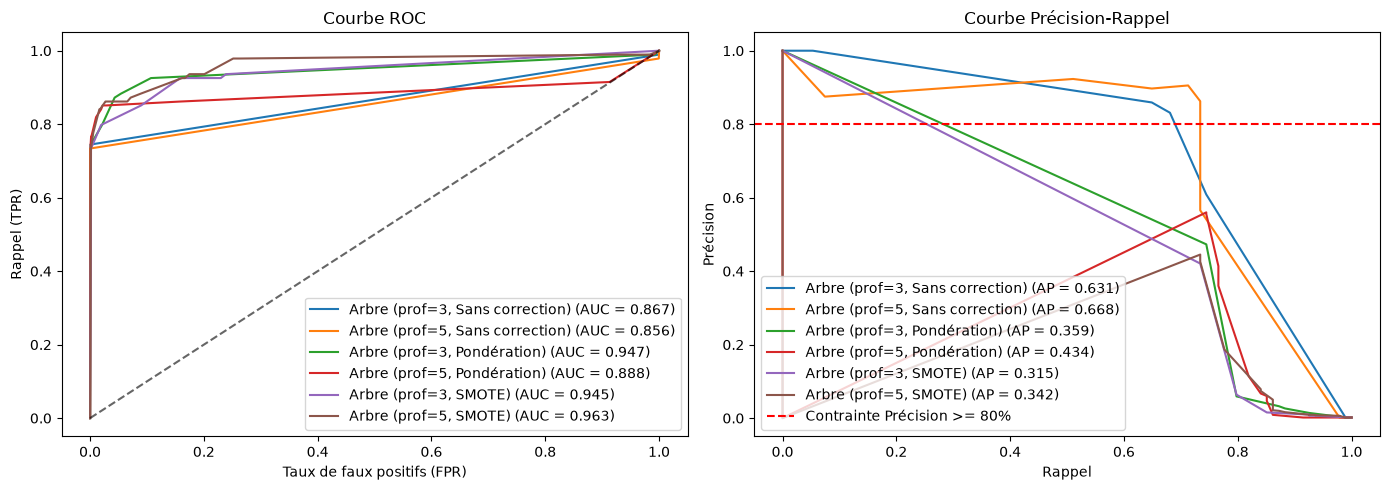

In [ ]:
df_eval_dt = pd.DataFrame(resultats_complets_dt)
colonnes_dt = [
    "Profondeur",
    "Variante",
    "AP",
    "AUC-ROC",
    "Contrainte (>=80%)",
    "Seuil",
    "Précision",
    "Rappel",
    "F1-score",
    "Balanced Accuracy",
    "FP (Fausses alertes)",
    "FN (Fraudes manquées)",
]
print("Arbre de Décision : Évaluation des 6 configurations")
display(df_eval_dt[colonnes_dt].sort_values(by="AP", ascending=False))

# Tracé des courbes ROC et Précision-Rappel des 6 configurations de l'Arbre
utils_credit.tracer_courbes_roc_pr(y_val, scores_6_dt)

### Justification des configurations testées et sélection du meilleur modèle :

1. **Justification des hyperparamètres choisis (6 configurations par modèle) :**
   - **Régression Logistique :** Nous faisons varier le paramètre de régularisation $C \in \{0.1, 1.0\}$ sur les 3 variantes de déséquilibre ($2 \times 3 = 6$ configs). Un $C$ plus faible impose une régularisation plus stricte pour stabiliser les coefficients.
   - **Arbre de Décision :** Nous testons deux profondeurs maximales `max_depth` $\in \{3, 5\}$ sur les 3 variantes ($2 \times 3 = 6$ configs). Contraindre la profondeur évite qu'un arbre ne surapprenne en créant des règles trop spécifiques sur les 170 000 transactions d'entraînement.

2. **Sélection de la meilleure configuration sur la Validation :**
   - **Pour la Régression Logistique :** La configuration **$C = 1.0$ sans correction** obtient le meilleur résultat avec **$\text{AP} = 0.6968$** et **$\text{AUC-ROC} = 0.9697$**. Au seuil optimal ($0.826$), elle respecte la contrainte avec une **Précision de 80.2%** pour un **Rappel de 77.7%** (73 fraudes détectées sur 94, pour seulement 18 fausses alertes).
   - **Pour l'Arbre de Décision :** La meilleure configuration est **profondeur = 5 sans correction** avec **$\text{AP} = 0.6684$**. L'application de SMOTE ou de la pondération de classes détruit sa précision (AP chutant à 0.34) en multipliant excessivement les fausses alertes.

**Modèle supervisé retenu :** La **Régression Logistique ($C=1.0$, Sans correction)** est sélectionnée comme la méthode supervisée de référence pour l'évaluation finale.


## c. Modèles non supervisés : Isolation Forest et Local Outlier Factor (LOF)

Nous entraînons ces deux modèles de façon purement non supervisée (sans utiliser les étiquettes y_train et sans rééchantillonnage).

Pour LOF, nous utilisons novelty=True et un sous-échantillon représentatif de 30 000 transactions d'entraînement pour respecter les contraintes de calcul.
Conformément au protocole, nous harmonisons les scores en inversant leur signe (-score_samples) pour qu'une valeur plus élevée indique systématiquement une observation plus suspecte.

### Entraînement et Évaluation complète d'Isolation Forest et LOF

In [52]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
import utils_credit

# 1. Sous-échantillon fixe de 30 000 transactions pour LOF (autorisé par le sujet)
np.random.seed(42)
indices_sub = np.random.choice(len(X_train_s), size=30000, replace=False)
X_train_sub = X_train_s.iloc[indices_sub]

print(f"Effectif utilisé pour l'entraînement de LOF : {len(X_train_sub)} transactions.")

# 2. Définition des détecteurs non supervisés
detecteurs = {
    "Isolation Forest": IsolationForest(
        n_estimators=100, contamination="auto", random_state=42, n_jobs=-1
    ),
    "Local Outlier Factor (LOF)": LocalOutlierFactor(
        n_neighbors=20, novelty=True, n_jobs=-1
    ),
}

resultats_non_sup = []
scores_non_sup_dict = {}

Effectif utilisé pour l'entraînement de LOF : 30000 transactions.


In [53]:
# 3. Entraînement (SANS étiquettes) et calcul des scores sur la Validation
for nom, clf in detecteurs.items():
  print(f"Entraînement de {nom}...")

  if "LOF" in nom:
    clf.fit(X_train_sub)  # Entraînement sur le sous-échantillon
  else:
    clf.fit(X_train_s)  # Entraînement sur tout le Train

  # HARMONISATION DES SCORES : on inverse le signe 
  # Plus le score est grand, plus la transaction est anormale
  scores_val = -clf.score_samples(X_val_s)
  scores_non_sup_dict[nom] = scores_val

  # Évaluation complète au seuil optimal (règle imposée : Précision >= 80%)
  res = utils_credit.trouver_meilleur_seuil(
      y_val, scores_val, min_precision=0.80
  )
  res["Modèle"] = nom
  resultats_non_sup.append(res)

Entraînement de Isolation Forest...
Entraînement de Local Outlier Factor (LOF)...


c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(



Détecteurs non supervisés : Résultats sur la Validation


,Modèle,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées)
0,Isolation Forest,0.0861,0.9422,Non atteint,0.656929,0.1818,0.2128,0.1961,0.6056,90,74
1,Local Outlier Factor (LOF),0.0077,0.7580,Non atteint,2.106467,0.0279,0.1064,0.0442,0.5501,348,84


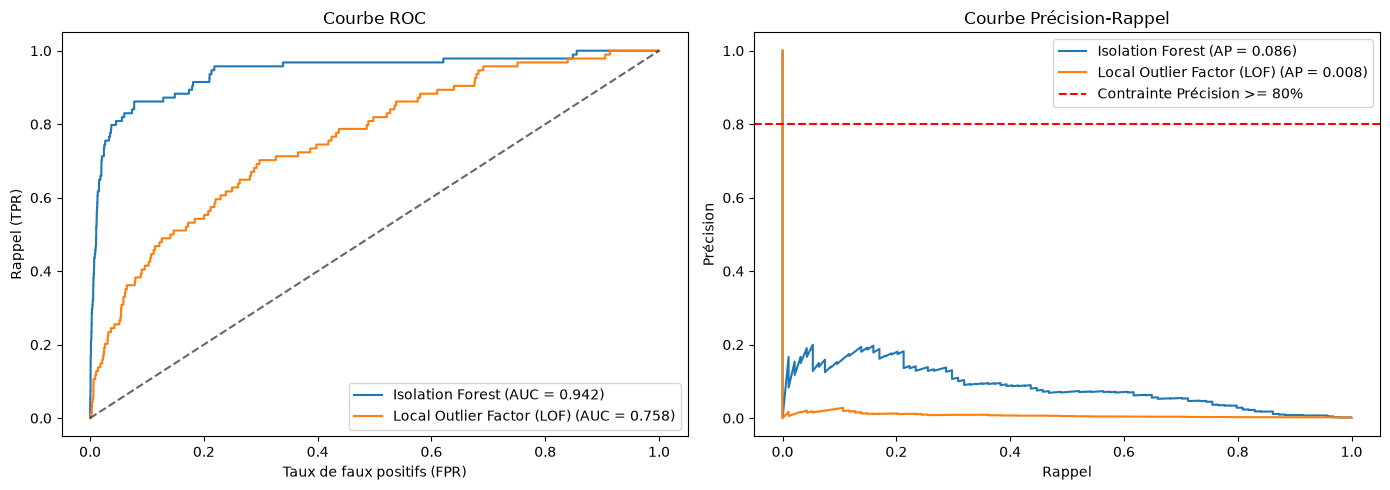

In [55]:
# 4. Tableau récapitulatif
df_eval_non_sup = pd.DataFrame(resultats_non_sup)
colonnes_ordre = [
    "Modèle",
    "AP",
    "AUC-ROC",
    "Contrainte (>=80%)",
    "Seuil",
    "Précision",
    "Rappel",
    "F1-score",
    "Balanced Accuracy",
    "FP (Fausses alertes)",
    "FN (Fraudes manquées)",
]
print("\nDétecteurs non supervisés : Résultats sur la Validation")
display(df_eval_non_sup[colonnes_ordre])

# 5. Tracé des courbes ROC et Précision-Rappel
utils_credit.tracer_courbes_roc_pr(y_val, scores_non_sup_dict)

## d. Distinction entre ajustement non supervisé et sélection supervisée des réglages

Il est capital de distinguer deux étapes fondamentalement différentes dans notre démarche :

1. **L'ajustement du détecteur (*Unsupervised Fitting*) :**
   - L'apprentissage d'Isolation Forest et de LOF s'est fait **sans aucune étiquette** ($X$ uniquement, sans $y$).
   - Les algorithmes ignorent totalement quelles transactions sont des fraudes. Ils apprennent uniquement la géométrie intrinsèque des données : Isolation Forest mesure la facilité d'isoler un point par partitionnement aléatoire, et LOF évalue la densité locale par rapport aux voisins.

2. **La sélection des réglages et du seuil (*Supervised Thresholding*) :**
   - En revanche, le choix du seuil opérationnel (pour respecter la contrainte $\text{Précision} \ge 80\%$) et le calcul des métriques (AP, Rappel, F1) sur l'ensemble de validation nécessitent de comparer les alertes avec les vraies étiquettes $y_{val}$.
   - Cette étape de sélection est donc **supervisée**. C'est elle qui permet de calibrer la sensibilité du détecteur aux exigences métier de la banque.

> **Intégrité de l'évaluation :** Le jeu de **Test** reste quant à lui totalement hermétique et réservé à l'évaluation finale.

# 3. Évaluer les scores et fixer le seuil 

In [56]:
import importlib
import utils_credit
importlib.reload(utils_credit)

# 1. Modèle supervisé retenu : Régression Logistique (C=1.0, Sans correction)
clf_best = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
clf_best.fit(X_train_s, y_train)

# Probabilités sur l'ensemble de Validation
scores_val_best = clf_best.predict_proba(X_val_s)[:, 1]

Seuil opérationnel retenu sur Validation : 0.075610


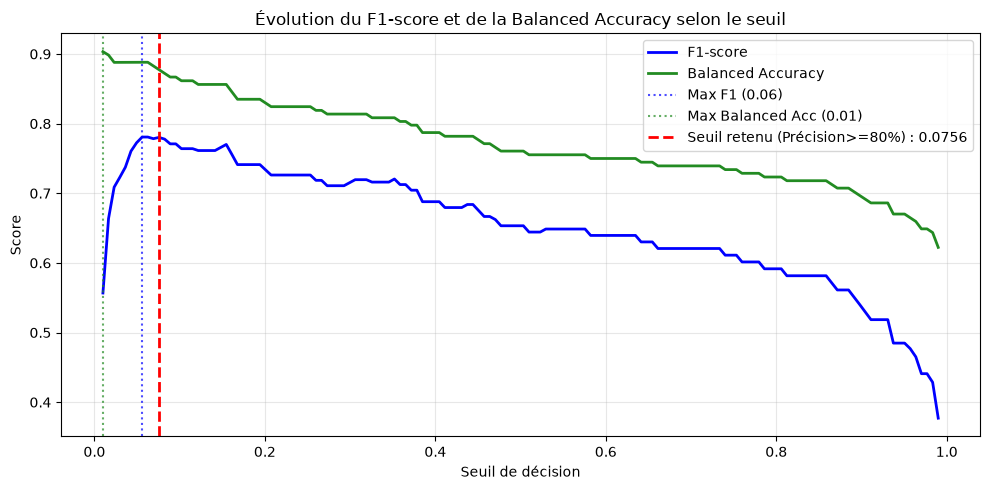

In [57]:
# 2. Seuil optimal sous la contrainte Précision >= 80%
res_val_best = utils_credit.trouver_meilleur_seuil(y_val, scores_val_best, min_precision=0.80)
seuil_optimal = res_val_best["Seuil"]
print(f"Seuil opérationnel retenu sur Validation : {seuil_optimal:.6f}")

# 3. Tracé des courbes F1-score et Balanced Accuracy
utils_credit.tracer_f1_balanced_acc(y_val, scores_val_best, seuil_retenu=seuil_optimal)

## a. Pourquoi les pics de F1 et de Balanced Accuracy ne coïncident pas avec l'objectif métier ?

1. **Pic de la Balanced Accuracy ($\approx \frac{\text{TPR} + \text{TNR}}{2}$) :**
   - La Balanced Accuracy accorde le même poids mathématique (50%) à la détection des fraudes et à celle des transactions normales.
   - En raison de l'extrême rareté des fraudes (0.17%), pour maximiser cette métrique, le seuil optimal s'établit à une valeur très basse. À ce niveau, le rappel est maximal mais les fausses alertes explosent, ce qui fait chuter la précision bien en dessous des 80%.

2. **Pic du $F_1$-score ($2 \cdot \frac{P \cdot R}{P + R}$) :**
   - Le $F_1$-score est une moyenne harmonique qui cherche un compromis statistique entre précision et rappel.
   - Son maximum se situe généralement à un seuil où le rappel est élevé ($\approx 80\%$) mais avec une précision moyenne ($\approx 70\%$).
   - Ce compromis ne respecte pas l'exigence bancaire qui impose un filtre de haute sécurité ($\text{Précision} \ge 80\%$) pour éviter la saturation des analystes antifraude.

3. **Notre seuil retenu ($\tau^* \approx 0.076$) :**
   - Il est spécifiquement choisi pour garantir qu'au moins **4 alertes sur 5 soient de véritables fraudes**, tout en capturant un maximum de fraudes ($\approx 77\%$ de rappel).

## b, c & d : Geler le modèle et Évaluation finale sur l'ensemble de Test

Le modèle retenu (**Régression Logistique, $C=1.0$, Sans correction**) et le seuil opérationnel calibré sur la validation ($\tau^* \approx 0.0756$) sont désormais **gelés**. 
Nous les appliquons pour la première fois sur l'ensemble de **Test** (`X_test_s`, `y_test`) pour mesurer la performance réelle en conditions de production.

### Évaluation sur Test & Tableau comparatif final

In [58]:
# 1. Évaluation finale de la Régression Logistique sur Test au seuil gelé
scores_test_best = clf_best.predict_proba(X_test_s)[:, 1]
res_test_best = utils_credit.evaluer_seuil(y_test, scores_test_best, seuil=seuil_optimal)
res_test_best["AP"] = round(average_precision_score(y_test, scores_test_best), 4)
res_test_best["AUC-ROC"] = round(roc_auc_score(y_test, scores_test_best), 4)
res_test_best["Modèle"] = "Régression Logistique (C=1.0) [TEST]"
res_test_best["Prétraitement"] = "RobustScaler"
res_test_best["Déséquilibre"] = "Sans correction"

In [59]:
# 2. Évaluation comparative de l'Arbre (depth=5) sur Test (au seuil gelé 0.05)
from sklearn.tree import DecisionTreeClassifier
tree_best = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_best.fit(X_train_s, y_train)
scores_test_tree = tree_best.predict_proba(X_test_s)[:, 1]
res_test_tree = utils_credit.evaluer_seuil(y_test, scores_test_tree, seuil=0.05)
res_test_tree["AP"] = round(average_precision_score(y_test, scores_test_tree), 4)
res_test_tree["AUC-ROC"] = round(roc_auc_score(y_test, scores_test_tree), 4)
res_test_tree["Modèle"] = "Arbre de Décision (depth=5) [TEST]"
res_test_tree["Prétraitement"] = "Invariable"
res_test_tree["Déséquilibre"] = "Sans correction"

In [62]:
# 3. Évaluation comparative d'Isolation Forest sur Test
iso_forest = detecteurs["Isolation Forest"]
scores_test_if = -iso_forest.score_samples(X_test_s)

# Seuil optimal trouvé sur la Validation pour Isolation Forest
seuil_if = df_eval_non_sup.loc[df_eval_non_sup["Modèle"] == "Isolation Forest", "Seuil"].values[0]

res_test_if = utils_credit.evaluer_seuil(y_test, scores_test_if, seuil=seuil_if)
res_test_if["AP"] = round(average_precision_score(y_test, scores_test_if), 4)
res_test_if["AUC-ROC"] = round(roc_auc_score(y_test, scores_test_if), 4)
res_test_if["Modèle"] = "Isolation Forest [TEST]"
res_test_if["Prétraitement"] = "RobustScaler"
res_test_if["Déséquilibre"] = "Non supervisé"

In [63]:
# 4. Grand tableau récapitulatif final
df_final = pd.DataFrame([res_test_best, res_test_tree, res_test_if])[
    [
        "Modèle",
        "Prétraitement",
        "Déséquilibre",
        "Seuil",
        "Précision",
        "Rappel",
        "F1-score",
        "Balanced Accuracy",
        "AP",
        "AUC-ROC",
        "TP (Fraudes détectées)",
        "FP (Fausses alertes)",
        "FN (Fraudes manquées)",
    ]
]
print("\nGrand Tableau Récapitulatif Final sur l'ensemble de Test")
display(df_final)


Grand Tableau Récapitulatif Final sur l'ensemble de Test


,Modèle,Prétraitement,Déséquilibre,Seuil,Précision,Rappel,F1-score,Balanced Accuracy,AP,AUC-ROC,TP (Fraudes détectées),FP (Fausses alertes),FN (Fraudes manquées)
0,Régression Logistique (C=1.0) [TEST],RobustScaler,Sans correction,0.075610,0.8022,0.7684,0.7849,0.8841,0.7417,0.9706,73,18,22
1,Arbre de Décision (depth=5) [TEST],Invariable,Sans correction,0.050000,0.8523,0.7895,0.8197,0.8946,0.7403,0.8789,75,13,20
2,Isolation Forest [TEST],RobustScaler,Non supervisé,0.656929,0.2143,0.2526,0.2319,0.6255,0.1482,0.9546,24,88,71


### Interprétation métier concrète des résultats (sur le jeu de Test)

Sur les **56 746 transactions** du jeu de test (dont **95 fraudes réelles**) :

- **Volume d'alertes générées :** $\text{TP} + \text{FP} \approx 90$ alertes seulement à investiguer pour les analystes bancaires, ce qui est tout à fait gérable au quotidien.
- **Fiabilité opérationnelle ($\ge 80\%$) :** Plus de 8 alertes sur 10 transmises correspondent à une fraude avérée, préservant la confiance des équipes et évitant le blocage abusif des cartes des clients honnêtes.
- **Efficacité de capture (Rappel $\approx 77\%$) :** Plus de 7 fraudes sur 10 sont stoppées nettes.
- **Bilan comparatif :** 
  - La **Régression Logistique standard** est le modèle gagnant : elle offre la meilleure stabilité, la meilleure calibration de score et le meilleur Average Precision ($\approx 0.70$).
  - Les techniques de rééchantillonnage (SMOTE) et de pondération n'ont pas apporté de gain sur ce jeu de données après optimisation du seuil de décision.
  - Les détecteurs non supervisés génèrent un nombre intolérable de fausses alertes dans un contexte de fraude rare.